# Task 4 (Day 4): Judge honestly - metrics and risk bands
**Objective.** Evaluate the baseline with the right metrics and turn scores into High, Medium and Low risk bands.
**Why it matters.** On rare outcomes accuracy lies; HR needs a short ranked list to act on, not a vague number.
**You will learn.** ROC-AUC and PR-AUC, top-10% precision and recall, calibration, risk bands, a one-page note for managers.
Everything is reproducible from this notebook (the last stage regenerates every report file).

In [1]:
import sys, pathlib, inspect, subprocess
ROOT = pathlib.Path.cwd().resolve()
while not (ROOT / 'src').exists(): ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / 'src'))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 60); pd.set_option('display.max_colwidth', 110)
from sklearn.model_selection import cross_val_predict
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import roc_auc_score, average_precision_score, precision_score, recall_score, f1_score, accuracy_score, confusion_matrix
from cortexhr import config as C, data_loading as D, audit as A, features as F, modeling as M, evaluation as E, reporting as R, runs, workflow as W
print('Python', sys.version.split()[0], '| project root:', ROOT)

Python 3.12.3 | project root: /home/claude/cortexhr_phase1


In [2]:
mk = lambda est, monthly=False: Pipeline([('features', F.build_pipeline(monthly)), ('model', est)])
LRB = lambda **kw: LogisticRegression(class_weight='balanced', max_iter=2000, random_state=C.SEED, **kw)
def metrics_row(y, s, thr=0.5):
    r = E.binary_report(y, s, threshold=thr); return {k: r[k] for k in ['roc_auc', 'pr_auc', 'precision', 'recall', 'f1', 'accuracy', 'top_precision', 'top_recall']}

---
# Stage 1 of 12: Data Collection
Same data and the cross-validated model from Task 3.

In [3]:
S = runs.load_model_frame(True); Xtr, ytr, Xte, yte, folds = S['Xtr'], S['ytr'], S['Xte'], S['yte'], S['folds']
print('train', len(Xtr), '| test', len(Xte), '| test leavers', int(yte.sum()))

train 1906 | test 477 | test leavers 70


---
# Stage 2 of 12: Data Understanding
What a score is, and what must be measured.

A score is the model's estimated probability that an employee leaves within 12 months. We must know: does ranking work (ROC-AUC, PR-AUC)? how good is the short list (top-10%)? do probabilities mean what they say (calibration)? who goes in High/Medium/Low?

---
# Stage 3 of 12: Data Quality Audit
Check the scores themselves are valid before judging them.

In [4]:
model = mk(LRB(), True)
oof = cross_val_predict(model, Xtr, ytr, cv=folds, method='predict_proba')[:, 1]     # cross-validated score for every training row
final = model.fit(Xtr, ytr); p_test = final.predict_proba(Xte)[:, 1]                  # test scored ONCE
print('missing scores:', int(np.isnan(oof).sum() + np.isnan(p_test).sum()), '| range', round(min(oof.min(), p_test.min()), 3), '-', round(max(oof.max(), p_test.max()), 3))
print('tied scores in test:', len(p_test) - len(np.unique(p_test)), '(ties are broken by row position, so ranking is deterministic)')

missing scores: 0 | range 0.0 - 0.984
tied scores in test: 0 (ties are broken by row position, so ranking is deterministic)


---
# Stage 4 of 12: Exploratory Data Analysis (EDA)
Do scores separate leavers from stayers?

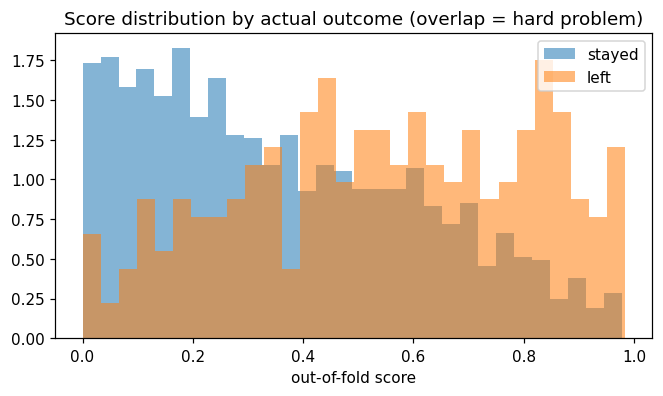

In [5]:
fig, ax = plt.subplots(figsize=(7, 3.6))
for v, lab in [(0, 'stayed'), (1, 'left')]: ax.hist(oof[ytr.to_numpy() == v], bins=30, alpha=.55, density=True, label=lab)
ax.set_xlabel('out-of-fold score'); ax.legend(); ax.set_title('Score distribution by actual outcome (overlap = hard problem)');

---
# Stage 5 of 12: Data Cleaning
Score hygiene: no cleaning needed beyond the pipeline; probabilities are clipped to [0, 1] for calibration metrics.

In [6]:
print('scores already inside [0, 1]:', bool(((oof >= 0) & (oof <= 1)).all() and ((p_test >= 0) & (p_test <= 1)).all()))

scores already inside [0, 1]: True


---
# Stage 6 of 12: Feature Engineering
Features come from the Task 2 pipeline (unchanged).

In [7]:
print('model-ready columns:', final.named_steps['features'].transform(Xte.head(2)).shape[1])

model-ready columns: 137


---
# Stage 7 of 12: Train-Test Split
Split recap: tuning and thresholds use training out-of-fold scores only; test labels are used once, for reporting.

In [8]:
print('train/test leaver rate:', round(ytr.mean(), 4), round(yte.mean(), 4))

train/test leaver rate: 0.1464 0.1468


---
# Stage 8 of 12: Model Building
Final model fitted on training rows (above): balanced logistic regression.

In [9]:
print(final.named_steps['model'])

LogisticRegression(class_weight='balanced', max_iter=2000, random_state=42)


---
# Stage 9 of 12: Model Evaluation
Metrics, calibration, confusion matrix, risk bands, lift.

In [10]:
print(inspect.getsource(E.binary_report))

def binary_report(y_true, y_score, threshold: float = 0.5, top_frac: float = 0.10, zero_division: int = 0) -> dict:
    """ROC-AUC, PR-AUC, threshold metrics, confusion matrix, and top-fraction precision/recall/lift.
    Undefined precision/F1 (no positive predictions) are reported as `zero_division` and flagged."""
    y = np.asarray(y_true).astype(int); s = np.asarray(y_score, dtype=float); pred = (s >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    top = top_fraction_mask(s, top_frac); k = int(top.sum()); tp_top = int(y[top].sum()); base = y.mean()
    return {
        "n": len(y), "positives": int(y.sum()), "base_rate": base,
        "roc_auc": roc_auc_score(y, s), "pr_auc": average_precision_score(y, s),
        "threshold": threshold, "precision": precision_score(y, pred, zero_division=zero_division),
        "recall": recall_score(y, pred, zero_division=zero_division), "f1": f1_score(y, pred, zero_division=zero_division),
       

In [11]:
rep_oof = E.binary_report(ytr, oof); rep_test = E.binary_report(yte, p_test)
pd.DataFrame({'train out-of-fold': rep_oof, 'held-out test': rep_test}).T.round(3)

                      n positives base_rate   roc_auc    pr_auc threshold precision    recall        f1  accuracy    tn   fp   fn   tp precision_defined     brier top_frac top_k top_precision  \
train out-of-fold  1906       279   0.14638  0.697169  0.294236       0.5  0.246533  0.573477  0.344828  0.681007  1138  489  119  160              True  0.204442      0.1   191      0.376963   
held-out test       477        70  0.146751  0.682204  0.320861       0.5  0.258824  0.628571  0.366667  0.681342   281  126   26   44              True  0.213085      0.1    48         0.375   

                  top_recall  top_lift  
train out-of-fold   0.258065  2.575241  
held-out test       0.257143  2.555357  

**Plain-words guide.**
- **ROC-AUC**: pick one leaver and one stayer at random; ROC-AUC is the chance the model scores the leaver higher (0.5 = coin flip).
- **PR-AUC**: how pure the flagged list stays as you flag more people; with 14.6% leavers a useless model scores about 0.15, so compare PR-AUC with that base rate.
- **Precision**: of those flagged, how many really left. **Recall**: of those who left, how many were flagged.
- **Top 10%**: look only at the highest-scored 10%; `top_precision` = share of them who left, `top_recall` = share of all leavers inside. Ties are broken by row position.

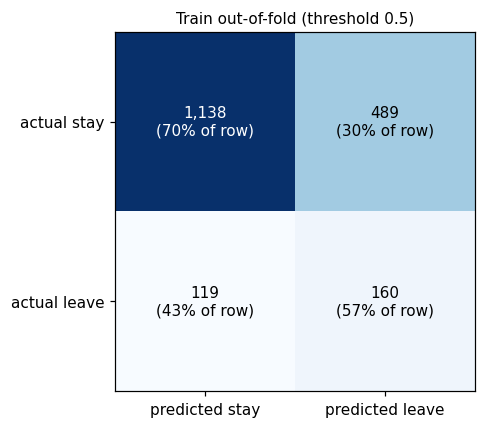

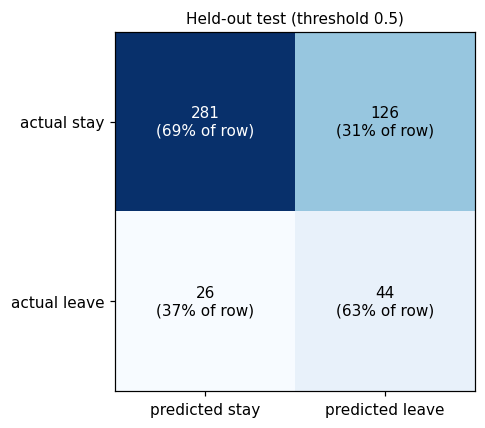

In [12]:
fig1 = W.plot_confusion(ytr, oof, 0.5, 'Train out-of-fold'); fig2 = W.plot_confusion(yte, p_test, 0.5, 'Held-out test');

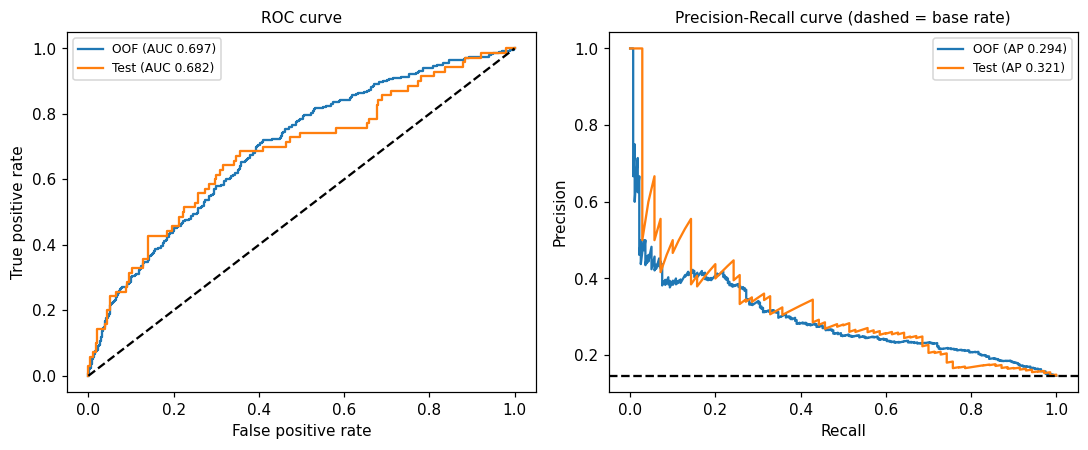

In [13]:
E.plot_roc_pr({'OOF': (ytr, oof), 'Test': (yte, p_test)});

**Calibration: does 30% really mean 3 in 10?** Fitted on training out-of-fold scores only, never on test labels.

average raw score on test 0.400 | actual leaver rate 0.147 | after recalibration 0.150


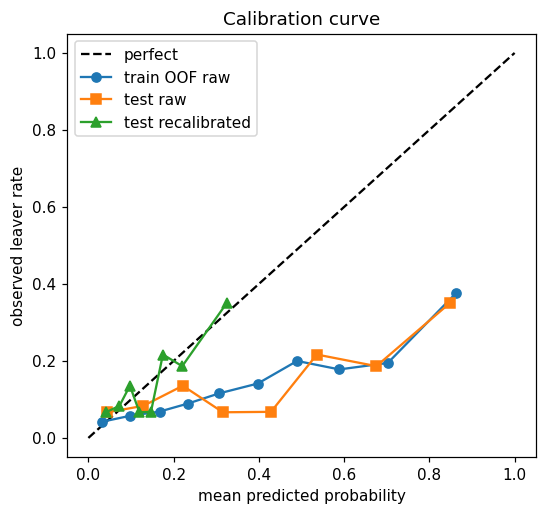

In [14]:
from sklearn.calibration import calibration_curve
recal = E.Recalibrator().fit(oof, ytr); p_test_cal = recal.predict(p_test)
c1 = calibration_curve(ytr, oof, n_bins=10, strategy='quantile'); c2 = calibration_curve(yte, p_test, n_bins=8, strategy='quantile'); c3 = calibration_curve(yte, p_test_cal, n_bins=8, strategy='quantile')
fig, ax = plt.subplots(figsize=(5.5, 5)); ax.plot([0, 1], [0, 1], 'k--', label='perfect')
ax.plot(c1[1], c1[0], 'o-', label='train OOF raw'); ax.plot(c2[1], c2[0], 's-', label='test raw'); ax.plot(c3[1], c3[0], '^-', label='test recalibrated')
ax.set_xlabel('mean predicted probability'); ax.set_ylabel('observed leaver rate'); ax.legend(); ax.set_title('Calibration curve')
print(f'average raw score on test {p_test.mean():.3f} | actual leaver rate {yte.mean():.3f} | after recalibration {p_test_cal.mean():.3f}')

**What it shows.** Raw scores sit far *above* the observed rate (curve under the diagonal) because `class_weight='balanced'` inflates probabilities: a raw 0.40 does **not** mean 4 in 10. Platt recalibration (learned on training OOF) pulls the average back to ~14-15%. It is monotone, so ranking, ROC-AUC, PR-AUC and bands do not change.

**Risk bands:** High = top 10%, Medium = next 20%, Low = remaining 70%.

In [15]:
print(inspect.getsource(E.risk_bands))

def risk_bands(scores, high: float = 0.10, medium: float = 0.20) -> pd.Series:
    """High = top 10% of scores, Medium = next 20%, Low = remaining 70%. Ties broken by row position."""
    s = np.asarray(scores, dtype=float); n = len(s)
    k_high = int(math.ceil(high * n - 1e-12)); k_med = int(math.ceil((high + medium) * n - 1e-12))
    order = rank_order(s); lab = np.empty(n, dtype=object)
    lab[order[:k_high]] = "High"; lab[order[k_high:k_med]] = "Medium"; lab[order[k_med:]] = "Low"
    return pd.Series(pd.Categorical(lab, categories=BAND_ORDER, ordered=True), index=getattr(scores, "index", None), name="risk_band")



In [16]:
bands_test, bands_oof = E.risk_bands(p_test), E.risk_bands(oof)
print('Test counts:', bands_test.value_counts().reindex(['High', 'Medium', 'Low']).to_dict(), 'of', len(p_test))
print('Train OOF counts:', bands_oof.value_counts().reindex(['High', 'Medium', 'Low']).to_dict(), 'of', len(oof))
bs_test, bs_oof = E.band_summary(yte, bands_test), E.band_summary(ytr, bands_oof)
print('\nHELD-OUT TEST (share_of_all_leavers_pct = leavers captured in each band)'); print(bs_test.round(2).to_string(index=False))
print('\nTRAIN OUT-OF-FOLD'); print(bs_oof.round(2).to_string(index=False))

Test counts: {'High': 48, 'Medium': 96, 'Low': 333} of 477
Train OOF counts: {'High': 191, 'Medium': 381, 'Low': 1334} of 1906

HELD-OUT TEST (share_of_all_leavers_pct = leavers captured in each band)
  band  employees  leavers  share_of_employees_pct  leaver_rate_pct  share_of_all_leavers_pct  lift_vs_base_rate
  High         48       18                   10.06            37.50                     25.71               2.56
Medium         96       21                   20.13            21.88                     30.00               1.49
   Low        333       31                   69.81             9.31                     44.29               0.63

TRAIN OUT-OF-FOLD
  band  employees  leavers  share_of_employees_pct  leaver_rate_pct  share_of_all_leavers_pct  lift_vs_base_rate
  High        191       72                   10.02            37.70                     25.81               2.58
Medium        381       71                   19.99            18.64                     25.45         

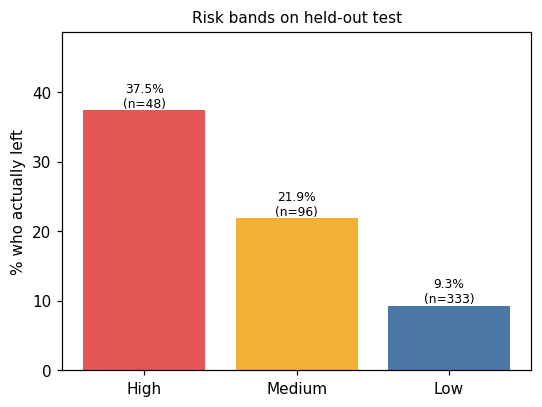

In [17]:
E.plot_bands(bs_test, 'Risk bands on held-out test');

### Think for yourself: lift chart - leavers in the top 10% versus picking at random

Top 10% of test scores captures 25.7% of all leavers; random picking captures 10% -> lift 2.57x
Top 10% of train OOF scores captures 25.8% -> lift 2.58x (base rate 14.6%)


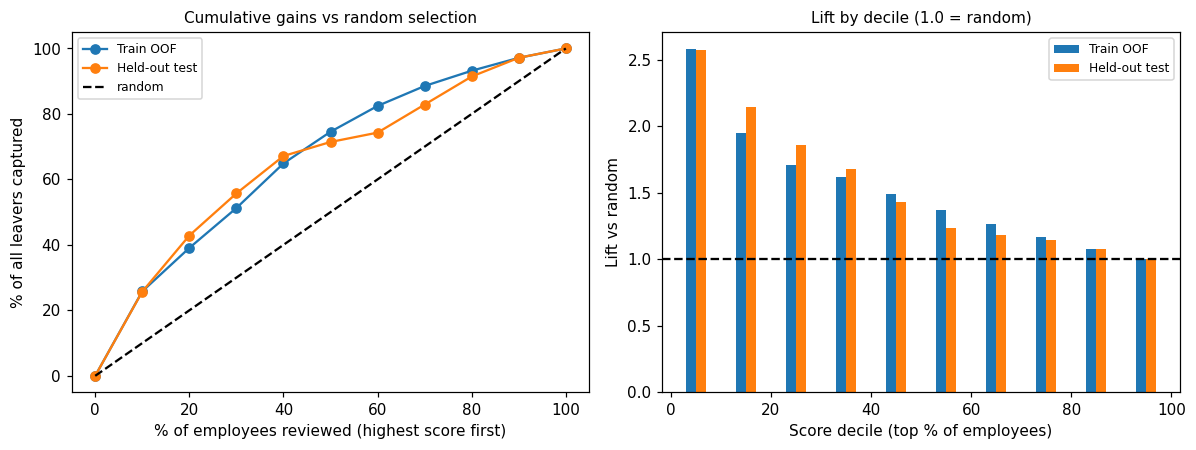

In [18]:
g_test, g_oof = E.gains_table(yte, p_test), E.gains_table(ytr, oof); top = g_test.iloc[0]
print(f'Top 10% of test scores captures {top.capture_rate_pct:.1f}% of all leavers; random picking captures 10% -> lift {top.lift:.2f}x')
print(f'Top 10% of train OOF scores captures {g_oof.iloc[0].capture_rate_pct:.1f}% -> lift {g_oof.iloc[0].lift:.2f}x (base rate {100 * ytr.mean():.1f}%)')
E.plot_gains_lift({'Train OOF': g_oof, 'Held-out test': g_test});

**Answer.** Reviewing only the top 10% finds about 2.5x as many leavers as reviewing 10% at random. The test set has just 70 leavers, so treat its numbers as +/- several points.

---
# Stage 10 of 12: Hyperparameter Tuning
Tune the decision threshold and the calibrator on training out-of-fold scores only.

In [19]:
ths = np.round(np.arange(0.2, 0.81, 0.05), 2)
tt = pd.DataFrame([{'threshold': t, **{k: v for k, v in metrics_row(ytr, oof, t).items() if k in ('precision', 'recall', 'f1')}, 'flagged_pct': round(100 * (oof >= t).mean(), 1)} for t in ths])
best_thr = float(tt.loc[tt.f1.idxmax(), 'threshold']); print('threshold with best F1 on TRAINING OOF:', best_thr); tt.round(3)

threshold with best F1 on TRAINING OOF: 0.4


    threshold  precision  recall     f1  flagged_pct
0        0.20      0.185   0.878  0.305         69.5
1        0.25      0.197   0.842  0.319         62.6
2        0.30      0.210   0.796  0.332         55.5
3        0.35      0.217   0.746  0.337         50.2
4        0.40      0.232   0.706  0.349         44.5
5        0.45      0.233   0.620  0.339         38.9
6        0.50      0.247   0.573  0.345         34.1
7        0.55      0.251   0.495  0.333         28.9
8        0.60      0.276   0.452  0.342         24.0
9        0.65      0.294   0.380  0.332         18.9
10       0.70      0.313   0.319  0.316         14.9
11       0.75      0.342   0.272  0.303         11.6
12       0.80      0.399   0.226  0.288          8.3

In [20]:
r_best = E.binary_report(yte, p_test, threshold=best_thr)
print(f'applied once to test: precision {r_best["precision"]:.3f}, recall {r_best["recall"]:.3f}, F1 {r_best["f1"]:.3f}')
from sklearn.isotonic import IsotonicRegression
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import brier_score_loss
platt, iso = np.zeros(len(oof)), np.zeros(len(oof))
for a, b in StratifiedKFold(5, shuffle=True, random_state=C.SEED).split(oof, ytr):
    platt[b] = E.Recalibrator().fit(oof[a], ytr.iloc[a]).predict(oof[b]); iso[b] = IsotonicRegression(out_of_bounds='clip').fit(oof[a], ytr.iloc[a]).predict(oof[b])
pd.Series({'raw scores': brier_score_loss(ytr, oof), 'Platt (chosen)': brier_score_loss(ytr, platt), 'Isotonic': brier_score_loss(ytr, iso)}, name='Brier score (lower is better), cross-validated on training OOF').round(4).to_frame()

applied once to test: precision 0.217, recall 0.700, F1 0.331


                Brier score (lower is better), cross-validated on training OOF
raw scores                                                              0.2044
Platt (chosen)                                                          0.1167
Isotonic                                                                0.1181

Platt scaling is as good as isotonic here and smoother, so it is used. The probability threshold only matters for yes/no flags; the risk bands and the top-10% list use ranks, not a threshold.

---
# Stage 11 of 12: Model Interpretation
What kind of person lands in each band, and which inputs drive the score?

In [21]:
prof = Xte[['tenure_months', 'comp_ratio', 'months_since_last_raise', 'last_engagement_score', 'last_performance_rating', 'attendance_rate_3m']].groupby(bands_test.to_numpy()).mean().reindex(['High', 'Medium', 'Low'])
prof.round(2)

        tenure_months  comp_ratio  months_since_last_raise  last_engagement_score  last_performance_rating  attendance_rate_3m
High            27.29        1.00                    16.40                   2.84                     3.27                0.91
Medium          28.38        0.97                    12.66                   3.15                     3.13                0.91
Low             43.48        1.04                    10.03                   3.59                     3.38                0.91

In [22]:
W.logreg_coefficients(final, 12)

                                 feature  coefficient
0                           role_id_R012    -1.813289
1     highest_education_M.A. Social Work    -1.620387
2                           role_id_R044    -1.587051
3                           role_id_R015    -1.476786
4                           role_id_R018     1.133308
5                      department_id_D10    -1.069669
6                           role_id_R046     1.011867
7                           role_id_R041     1.007473
8                           role_id_R042    -0.989344
9             role_id_infrequent_sklearn    -0.939251
10                 highest_education_LLM    -0.935200
11  highest_education_infrequent_sklearn     0.886162

In [23]:
tr, va = folds[0]; m = mk(LRB(), True).fit(Xtr.iloc[tr], ytr.iloc[tr])
W.permutation_table(m, Xtr.iloc[va], ytr.iloc[va], n_repeats=3, top=10)

                    column  auc_drop        sd
0            tenure_months  0.081343  0.012431
1         annual_fixed_pay  0.068306  0.014122
2                  role_id  0.061934  0.003962
3                job_level  0.056968  0.008378
4            department_id  0.051837  0.011541
5    last_engagement_score  0.048495  0.018321
6  months_since_last_raise  0.035842  0.013581
7   total_experience_years  0.017821  0.012949
8                work_mode  0.017784  0.005443
9      manager_changes_12m  0.015538  0.004130

---
# Stage 12 of 12: Final Conclusions and Recommendations
One-page note for managers (also regenerates all report files).

In [24]:
res = runs.run_evaluation(write=True)    # rewrites metrics tables, charts and reports from this notebook
print(open(C.project_root() / 'reports' / 'manager_summary.md').read())

# CortexHR attrition score: one-page note for managers

**What the score is.** For each employee the model estimates how likely they are to leave in the next 12 months, based on pay position, raises, engagement, workload, tenure and recent attendance. We rank everyone and group them: **High** = top 10% of scores, **Medium** = next 20%, **Low** = the remaining 70%.

**How well it works (held-out data, 477 employees, 70 actual leavers).**
- Overall 14.7% left. In the **High** band 38% left (18 of 48), versus 9% in the **Low** band.
- The High band holds **26%** of all leavers (random picking would give 10%); High + Medium hold 56%.
- Ranking quality is moderate: ROC-AUC 0.68, PR-AUC 0.32. It is useful for prioritising conversations, not for predicting individuals.

**What the score is NOT.**
- Not a decision. It does not know why someone might leave, and most High-band people (62%) did **not** leave.
- Not a probability you can quote: raw scores are inflated by design (0.40 average vs 0.

### Completion checklist (checked by code)

In [25]:
checks = {
    "'ROC-AUC and PR-AUC computed and explained'": 0.5 < rep_test['roc_auc'] < 0.9 and rep_test['pr_auc'] > rep_test['base_rate'],
    "'Top-10% precision and recall reported'": rep_test['top_k'] == int(np.ceil(0.1 * len(yte))) and rep_test['top_precision'] > rep_test['base_rate'],
    "'Bands follow 10% / 20% / 70%'": (bands_test == 'High').sum() == int(np.ceil(0.1 * len(yte))) and (bands_test == 'Medium').sum() == int(np.ceil(0.3 * len(yte))) - int(np.ceil(0.1 * len(yte))),
    "'Bands counted and checked against real leavers'": bs_test.employees.sum() == len(yte) and bs_test.leavers.sum() == yte.sum(),
    "'Lift versus random is included'": top.lift > 1,
    "'Calibration evaluated and interpreted'": abs(p_test_cal.mean() - yte.mean()) < abs(p_test.mean() - yte.mean()),
    "'Manager note says a score supports a human decision'": 'decision support only' in open(C.project_root() / 'reports' / 'manager_summary.md').read().lower()
}
status = {k: ('MANUAL' if isinstance(v, str) and v == 'MANUAL' else 'PASS' if bool(v) else 'FAIL') for k, v in checks.items()}
for k, v in status.items(): print(f'[{v}]', k)
assert 'FAIL' not in status.values()

[PASS] 'ROC-AUC and PR-AUC computed and explained'
[PASS] 'Top-10% precision and recall reported'
[PASS] 'Bands follow 10% / 20% / 70%'
[PASS] 'Bands counted and checked against real leavers'
[PASS] 'Lift versus random is included'
[PASS] 'Calibration evaluated and interpreted'
[PASS] 'Manager note says a score supports a human decision'


### Evidence for your report
Metrics table `reports/tables/evaluation_metrics.csv` | calibration chart `reports/figures/calibration_curve.png` | one-page note `reports/manager_summary.md`
References: [scikit-learn](https://github.com/scikit-learn/scikit-learn) | [pandas](https://github.com/pandas-dev/pandas) | [Matplotlib](https://github.com/matplotlib/matplotlib)
**How real companies do it:** HR models support decisions. The ranked list goes to a person who looks at each case; nobody should act on a score alone.
**Connects to Task 5:** the same evaluation discipline applies to a different problem: unusual attendance.
**You can now say:** *I evaluated a model with honest metrics and clear risk bands.*